# Лабораторная работа №2: Классификация (Titanic)

**Цель:** пройти полный цикл решения задачи классификации — от анализа данных и baseline до сравнения пяти алгоритмов, анализа метрик, ошибок и важности признаков.  
**Целевая переменная:** `Survived` (1 — выжил). **Основная метрика:** F1 для класса 1, порог **F1 > 0.70**.

Правила эксперимента: один стратифицированный split (`random_state=42`) для всех моделей; тест используется только для финальной оценки; гиперпараметры подбираются кросс-валидацией **только на train**; все преобразования обучаются только на train (внутри `Pipeline`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE, TEST_SIZE, F1_THRESHOLD = 42, 0.2, 0.70
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Первичный анализ данных

In [2]:
if Path("Titanic-Dataset.csv").exists():
    df = pd.read_csv("Titanic-Dataset.csv")
elif Path("archive.zip").exists():
    df = pd.read_csv("archive.zip")
else:
    raise FileNotFoundError("Положите Titanic-Dataset.csv или archive.zip рядом с ноутбуком")

print("Размер:", df.shape)
df.info()
miss = df.isna().sum()
print("\nПропуски (доля, %):\n", (miss[miss > 0] / len(df) * 100).round(1).to_string())
print("\nПолных дубликатов:", df.duplicated().sum())
print("Уникальных значений из 891:", df[["PassengerId", "Name", "Ticket", "Cabin"]].nunique().to_dict())
print("\nДоля выживших при известной/неизвестной каюте:",
      df.groupby(df.Cabin.isna())["Survived"].mean().round(2).to_dict(), "(False = известна)")
print("Доля выживших при известном/неизвестном возрасте:",
      df.groupby(df.Age.isna())["Survived"].mean().round(2).to_dict(), "(False = известен)")
df.head()

Размер: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Пропуски (доля, %):
 Age         19.9
Cabin       77.1
Embarked     0.2

Полных дубликатов: 0
Уникальных значений из 891: {'PassengerId': 891, 'Name': 891, 'Ticket': 681, 'Cabin': 147}

Доля выживших при известной/неизвестной каюте: {False:

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Признаки `Title` (обращение из `Name`; редкие объединены в `Rare`) и `FamilySize = SibSp + Parch + 1` строятся построчно, без обучения по данным, поэтому утечки при создании до разбиения нет.

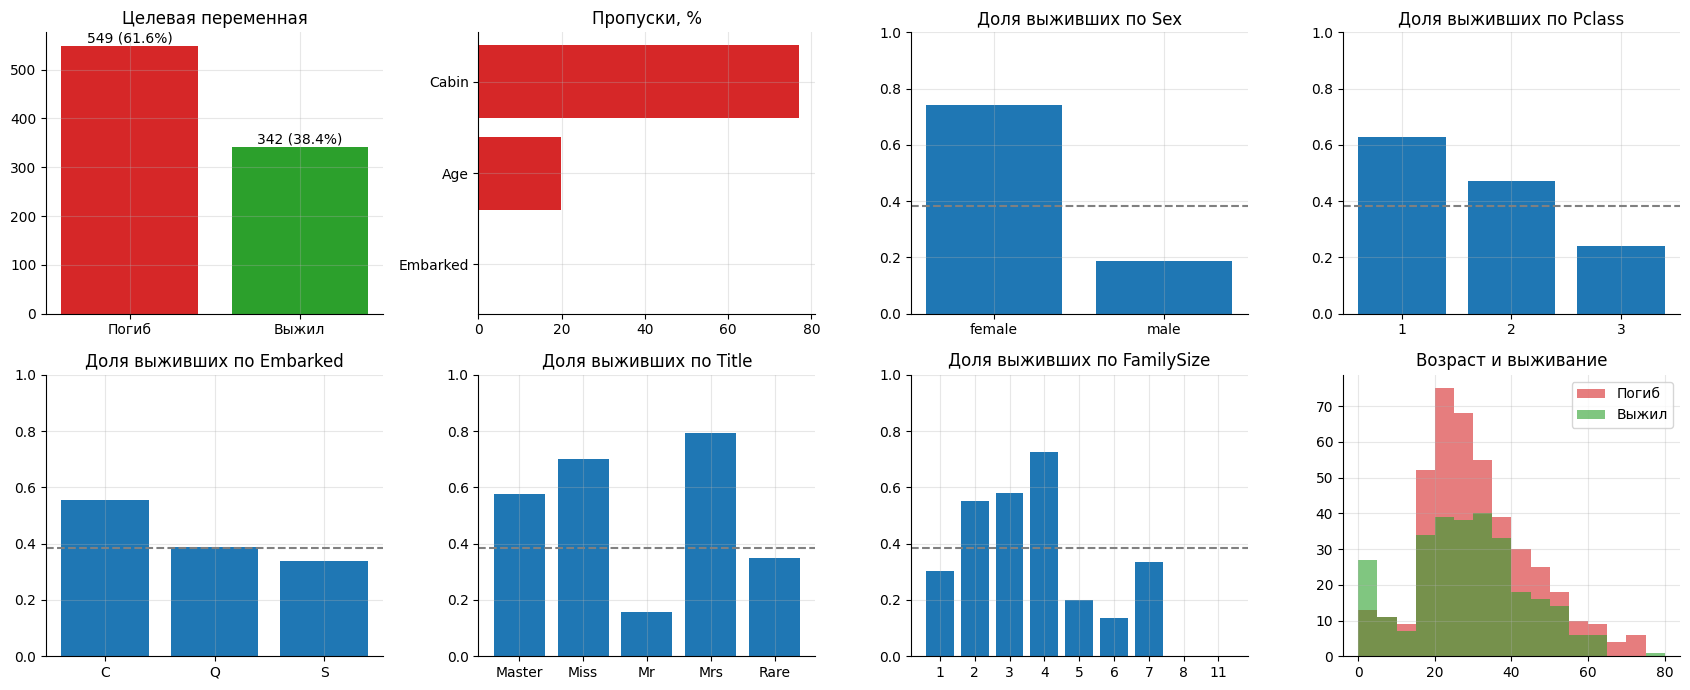

In [3]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
ax = axes[0, 0]; vc = df["Survived"].value_counts().sort_index()
bars = ax.bar(["Погиб", "Выжил"], vc.values, color=["tab:red", "tab:green"])
ax.bar_label(bars, labels=[f"{v} ({v/len(df):.1%})" for v in vc]); ax.set_title("Целевая переменная")

ax = axes[0, 1]; m = (df.isna().mean() * 100)[lambda s: s > 0].sort_values()
ax.barh(m.index, m.values, color="tab:red"); ax.set_title("Пропуски, %")

for ax, col in zip([axes[0, 2], axes[0, 3], axes[1, 0], axes[1, 1], axes[1, 2]],
                   ["Sex", "Pclass", "Embarked", "Title", "FamilySize"]):
    r = df.groupby(col)["Survived"].mean()
    ax.bar(r.index.astype(str), r.values, color="tab:blue")
    ax.axhline(df["Survived"].mean(), color="gray", ls="--"); ax.set_ylim(0, 1)
    ax.set_title(f"Доля выживших по {col}")

ax = axes[1, 3]; bins = np.arange(0, 85, 5)
for s, c, l in [(0, "tab:red", "Погиб"), (1, "tab:green", "Выжил")]:
    ax.hist(df.loc[df.Survived == s, "Age"].dropna(), bins=bins, alpha=0.6, color=c, label=l)
ax.set_title("Возраст и выживание"); ax.legend()
plt.tight_layout(); plt.show()

**Выводы по EDA**
- **Типы:** числовые `Age`, `Fare`, `SibSp`, `Parch`; категориальные `Pclass`, `Sex`, `Embarked`, `Title`; текстовые `Name`, `Ticket`, `Cabin`; `PassengerId` — идентификатор.
- **Пропуски:** `Cabin` — 77%, `Age` — 20%, `Embarked` — 2 строки. Дубликатов нет.
- **Цель:** 61.6% погибших и 38.4% выживших — умеренный дисбаланс. Константная модель «все погибли» даёт Accuracy ≈ 0.62, не находя ни одного выжившего, поэтому основная метрика — F1 класса 1, а разбиение — стратифицированное.
- **Признаки, требующие особой обработки:** `Age` (пропуски не случайны — пассажиры без возраста выживали реже, удалять строки нельзя); `Fare` (сильно скошен, дублирует класс); `FamilySize` (связь немонотонна: одиночки и семьи 5+ выживали реже).
- **Утечка и запоминание:** `PassengerId` и `Name` уникальны для каждой из 891 строк — модель могла бы запоминать пассажиров; `Ticket` — код группы (члены семьи делят билет и судьбу, группа может попасть и в train, и в test); `Cabin` — 77% пропусков, пропуск кодирует класс (в 1-м классе пропущено 18%, в 3-м 98%), а доля выживших при известной каюте 0.67 против 0.30 — каюты, по-видимому, фиксировали уже после события, то есть признак косвенно знает исход. Все четыре признака **исключаются**. Из `Name` берётся только обращение `Title` (5 значений) — оно никого не идентифицирует.
- **Главные сигналы:** пол/обращение (выжили ≈74% женщин и ≈19% мужчин), класс (63% / 47% / 24%), возраст (дети выживали чаще). `Embarked` связан с исходом лишь через состав классов.

## 2. Подготовка данных и выборок

Используются признаки `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Title, FamilySize`. Разбиение 80/20 со стратификацией (`stratify=y`) и `random_state=42`.

**Обработка (всё обучается только на train внутри `Pipeline`):**
- числовые пропуски (`Age`) — **медиана**: устойчива к выбросам и скошенным распределениям (`Age`, `Fare`);
- `Embarked` — **мода** (2 пропуска);
- категориальные признаки — **One-Hot** (не навязывает порядок/расстояния между категориями), `handle_unknown="ignore"`.

**Масштабирование (`StandardScaler`):**
- **Деревья, Random Forest, Gradient Boosting — не нужно:** сравнение признака с порогом зависит только от порядка значений, не от масштаба.
- **SVM (RBF) — нужно:** ядро зависит от евклидова расстояния; `Fare` (до 512) доминирует над `SibSp` (0–8) и искажает геометрию.
- **KNN — особенно нужно:** алгоритм целиком основан на расстоянии, соседей определяет признак с наибольшим масштабом.

Поэтому для деревьев — препроцессор без scaling, для SVM и KNN — со scaling.

In [4]:
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Title", "FamilySize"]
NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
CAT_COLS = ["Pclass", "Sex", "Embarked", "Title"]

X, y = df[FEATURES], df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape)
print("Доля класса 1: всего %.3f, train %.3f, test %.3f" % (y.mean(), y_train.mean(), y_test.mean()))

def make_preprocessor(scale, num_cols=NUM_COLS, cat_cols=CAT_COLS):
    num_steps = [("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

train: (712, 9) test: (179, 9)
Доля класса 1: всего 0.384, train 0.383, test 0.385


## 3. Метрики и Dummy baseline

- **Accuracy** — доля верных ответов (при дисбалансе завышена); **Precision** = TP/(TP+FP) — насколько можно верить предсказанию «выжил»; **Recall** = TP/(TP+FN) — какую долю выживших нашла модель; **F1** — их гармоническое среднее (основная метрика).
- **False Positive:** пассажир погиб, а модель предсказала, что выжил (переоценка шансов, «ложная надежда»). Снижает Precision.
- **False Negative:** пассажир выжил, а модель предсказала гибель (пропущенный выживший). Снижает Recall; при распределении мест в шлюпках это более «дорогая» ошибка.

Все модели оцениваются одной функцией. Гиперпараметры подбираются по F1 в 5-fold стратифицированной CV на train, малыми сетками. **Dummy baseline** всегда предсказывает самый частый класс.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, model, cv_f1=np.nan):
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p_te).ravel()
    return {"Model": name, "Accuracy": accuracy_score(y_test, p_te),
            "Precision": precision_score(y_test, p_te, zero_division=0),
            "Recall": recall_score(y_test, p_te), "F1": f1_score(y_test, p_te),
            "F1 train": f1_score(y_train, p_tr), "F1 CV (train)": cv_f1,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

specs = {
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), False,
                      {"max_depth": [2, 3, 4, 5, 6, 7, 8], "min_samples_leaf": [1, 3, 5, 10, 20]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), False,
                      {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 2, 4, 8]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), False,
                          {"n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [2, 3, 4]}),
    "SVM": (SVC(kernel="rbf", random_state=RANDOM_STATE), True,
            {"C": [0.5, 1, 3, 10], "gamma": ["scale", 0.01, 0.05, 0.1, 0.3]}),
    "KNN": (KNeighborsClassifier(), True,
            {"n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25, 31, 41, 51], "weights": ["uniform", "distance"]}),
}

fitted, rows = {}, []
dummy = Pipeline([("prep", make_preprocessor(False)), ("model", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
fitted["Dummy baseline"] = dummy
rows.append(evaluate("Dummy baseline", dummy))

for name, (est, scale, grid) in specs.items():
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", est)])
    gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()}, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    rows.append(evaluate(name, gs.best_estimator_, gs.best_score_))
    print(f"{name}: {({k.replace('model__', ''): v for k, v in gs.best_params_.items()})}")

deep = Pipeline([("prep", make_preprocessor(False)), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
print("\nДерево без ограничений (глубина %d): F1 train = %.3f, F1 test = %.3f" %
      (deep.named_steps["model"].get_depth(), f1_score(y_train, deep.predict(X_train)), f1_score(y_test, deep.predict(X_test))))

Decision Tree: {'max_depth': 3, 'min_samples_leaf': 1}
Random Forest: {'max_depth': 4, 'min_samples_leaf': 1}
Gradient Boosting: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200}
SVM: {'C': 3, 'gamma': 0.05}
KNN: {'n_neighbors': 31, 'weights': 'uniform'}

Дерево без ограничений (глубина 18): F1 train = 0.980, F1 test = 0.750


## 4. Результаты моделей и честное сравнение

Все модели обучены и оценены на одном разбиении, одной функцией. Колонка `F1 train` нужна для оценки переобучения, `F1 CV (train)` — оценка устойчивости, не зависящая от теста.

,Accuracy,Precision,Recall,F1,F1 train,F1 CV (train),TN,FP,FN,TP,F1 > 0.70
Model,,,,,,,,,,,
SVM,0.844,0.825,0.754,0.788,0.778,0.768,99,11,17,52,да
Decision Tree,0.832,0.800,0.754,0.776,0.785,0.763,97,13,17,52,да
Gradient Boosting,0.816,0.790,0.710,0.748,0.908,0.781,97,13,20,49,да
KNN,0.816,0.800,0.696,0.744,0.760,0.750,98,12,21,48,да
Random Forest,0.810,0.787,0.696,0.738,0.773,0.767,97,13,21,48,да
Dummy baseline,0.615,0.000,0.000,0.000,0.000,NaN,110,0,69,0,нет


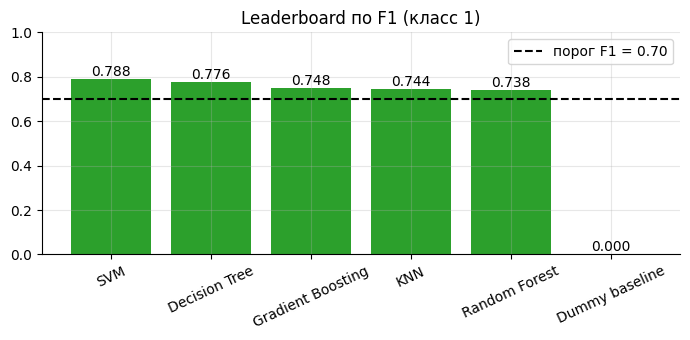

In [6]:
res = pd.DataFrame(rows).set_index("Model")
res["F1 > 0.70"] = np.where(res["F1"] > F1_THRESHOLD, "да", "нет")
leaderboard = res.sort_values("F1", ascending=False)
display(leaderboard.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(leaderboard.index, leaderboard["F1"], color=["tab:green" if v > F1_THRESHOLD else "tab:red" for v in leaderboard["F1"]])
ax.bar_label(bars, fmt="%.3f"); ax.axhline(F1_THRESHOLD, color="black", ls="--", label="порог F1 = 0.70")
ax.set(title="Leaderboard по F1 (класс 1)", ylim=(0, 1)); ax.tick_params(axis="x", rotation=25); ax.legend()
plt.tight_layout(); plt.show()

### Confusion matrix для каждой модели (тестовая выборка)

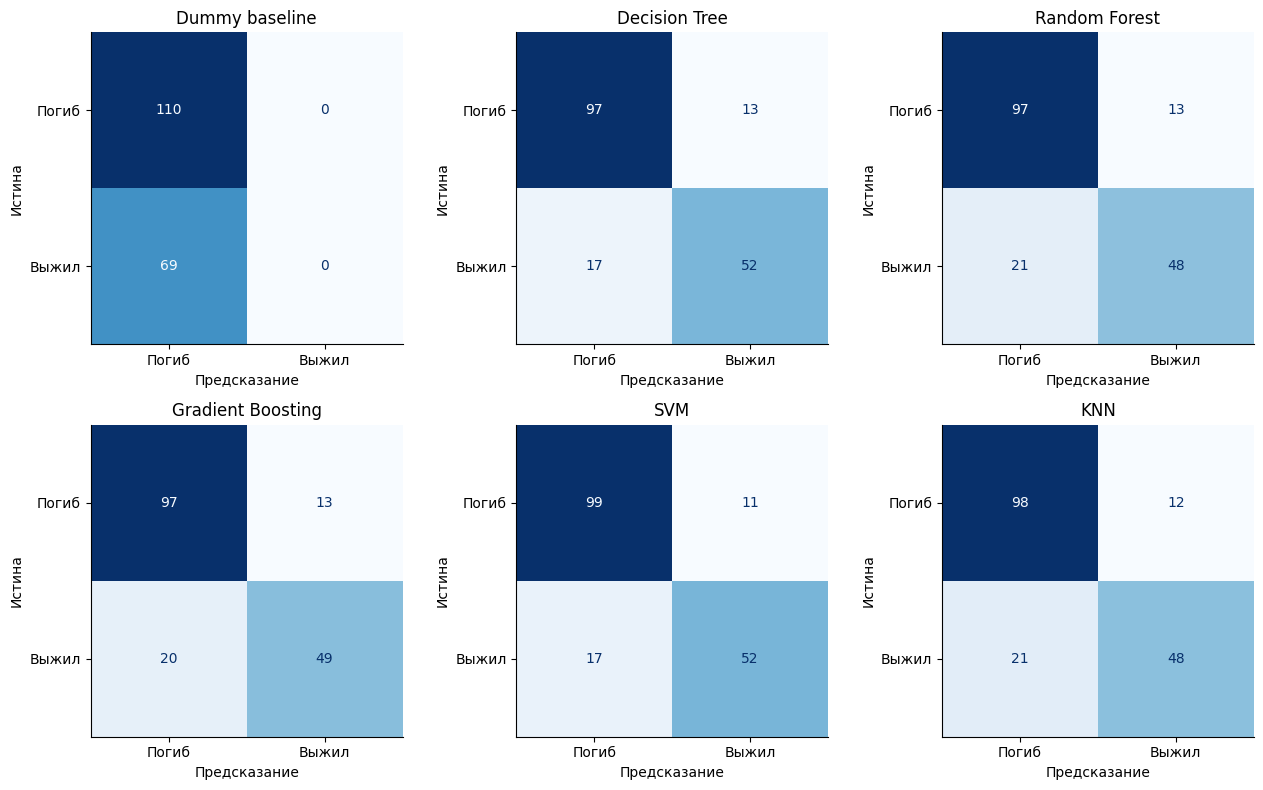

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, model) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["Погиб", "Выжил"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.grid(False); ax.set_title(name); ax.set_xlabel("Предсказание"); ax.set_ylabel("Истина")
plt.tight_layout(); plt.show()

**Какие ошибки делают модели.** Dummy baseline: Accuracy 0.615 только за счёт преобладания погибших, TP = 0, Recall = F1 = 0 (все 69 выживших — FN). У всех остальных моделей FP ≈ 11–13, FN ≈ 17–21: **выживших пропускают чаще (FN), чем ошибочно «спасают» погибших (FP)**, поэтому Precision (0.79–0.83) выше Recall (0.70–0.75), а F1 ограничен именно Recall.

**Порог F1 > 0.70:** его преодолели **все пять моделей** — SVM 0.788, Decision Tree 0.776, Gradient Boosting 0.748, KNN 0.744, Random Forest 0.738; baseline (F1 = 0) — нет. Все модели заметно лучше baseline и по Accuracy (0.81–0.84 против 0.615).

**Decision Tree и переобучение.** Дерево без ограничений (глубина 18) запоминает train (F1 ≈ 0.98) и даёт ≈ 0.75 на тесте — явное переобучение. Дерево с подобранными ограничениями (`max_depth=3`) имеет F1 на train 0.785 и на test 0.776 — **признаков переобучения нет**.

**Остальные модели:** у Random Forest, SVM и KNN F1 на train и test близки (разрыв ≤ 0.04). У Gradient Boosting train 0.91 против test 0.75 — **заметные признаки переобучения**: последовательная подгонка остатков сильнее адаптируется к train, чем усреднение независимых деревьев в лесу.

**Масштабирование:** SVM и KNN обучены на стандартизованных признаках (см. раздел 2); без этого `Fare` определял бы расстояния и качество заметно падало бы.

**Почему результаты различаются и различия невелики:**
- Данные небольшие, основной сигнал простой (пол/обращение, класс, возраст — «женщины и дети первыми»); его улавливает уже дерево глубины 3, сложные ансамбли не получают преимущества и склонны подгоняться под шум.
- Гиперпараметры выбраны по CV, поэтому порядок на тесте отличается от порядка по CV (по CV лучший — Gradient Boosting, 0.781).
- Тест мал (179 объектов, 69 положительных): одна ошибка меняет Recall на ≈ 1.4 п.п., поэтому разницы в 0.01–0.05 F1 лежат в пределах шума. SVM лучший именно на этом разбиении.
- SVM строит гладкую границу, подходящую малой выборке; KNN выбирает большое `k` (сильное сглаживание), так как судьбы пассажиров с одинаковым профилем неоднозначны.

## 5. Feature importance

Важность (убывание impurity) есть у трёх древовидных моделей. Чтобы сравнение не искажалось дроблением one-hot столбцов (`Sex_male`/`Sex_female`), важность суммируется по исходным признакам.

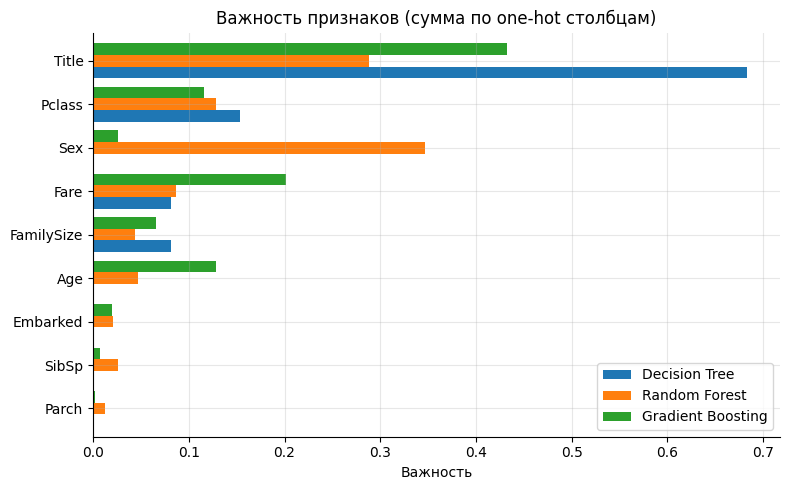

,Decision Tree,Random Forest,Gradient Boosting
Title,0.684,0.288,0.432
Pclass,0.154,0.128,0.116
Sex,0.000,0.347,0.026
Fare,0.081,0.087,0.202
FamilySize,0.082,0.044,0.065
Age,0.000,0.047,0.128
Embarked,0.000,0.020,0.020
SibSp,0.000,0.026,0.007
Parch,0.000,0.013,0.002


In [8]:
def importances(model):
    names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
    imp = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    return imp.groupby(lambda n: n.split("_")[0] if n.split("_")[0] in CAT_COLS else n).sum()

imp = pd.DataFrame({m: importances(fitted[m]) for m in ["Decision Tree", "Random Forest", "Gradient Boosting"]})
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]

imp[::-1].plot.barh(figsize=(8, 5), width=0.8)
plt.title("Важность признаков (сумма по one-hot столбцам)"); plt.xlabel("Важность"); plt.tight_layout(); plt.show()
imp.round(3)

**Наиболее важные признаки:** `Title` (несёт пол и возраст), `Sex` (в лесу), `Pclass`, затем `Fare`, `Age`, `FamilySize`; `Embarked`, `SibSp`, `Parch` — малозначимы.

**Сравнение моделей.**
- **Decision Tree** концентрирует важность в нескольких признаках (`Title` ≈ 0.68, `Pclass` 0.15, `FamilySize`, `Fare`); `Sex` у него 0, но не потому, что пол не важен: `Title` кодирует ту же информацию, и дерево выбрало его.
- **Random Forest** распределяет важность шире: `Sex` ≈ 0.35 и `Title` ≈ 0.29 делят между собой «пол», затем `Pclass`, `Fare`, `Age`. Это ответ на вопрос о сравнении с деревом: лес использует и `Sex`, и `Title` (случайный выбор признаков в узлах), а дерево — только `Title`; общий лидер — информация о поле/статусе.
- **Gradient Boosting** (`Title` ≈ 0.43) сильнее леса опирается на непрерывные `Fare` (≈ 0.20) и `Age` (≈ 0.13): суммарно ≈ 0.33 против ≈ 0.13 у леса. Последовательные деревья дообучаются на остатках, где остаются эти признаки. Кроме того, impurity-importance завышает признаки с большим числом порогов (`Fare`, `Age`).

**Соотнесение с EDA.** Результаты согласуются с первичным анализом: сильнейшие сигналы — пол/обращение, класс, возраст; `FamilySize` вносит вклад (немонотонная связь); `Embarked` в EDA выглядел связанным с исходом, но модели его почти не используют — связь объяснялась составом классов; `Fare` важен как заместитель класса.

**Можно ли утверждать, что важный признак — причина выживания? Нет.** Важность показывает, насколько признак использован моделью для *предсказания*, а не как изменится исход при его изменении. Данные наблюдательные, есть заместители и конфаундеры: `Fare` отражает класс и расположение каюты, а не «цена билета спасает»; `Title_Mr` отражает пол и возраст; сам пол — это не биологическая причина, а следствие социального правила «женщины и дети первыми» при посадке в шлюпки. Коррелированные признаки делят важность произвольно (`Sex`/`Title`), и она зависит от алгоритма (у трёх моделей она разная). Для причинных выводов нужны эксперименты или методы причинного вывода.

## 6. Анализ ошибок лучшей модели

Лучшая по F1 — определяется автоматически.

Лучшая модель: SVM
TN=99 FP=11 FN=17 TP=52
FPR (погибшие, названные выжившими) = 0.100;  FNR (пропущенные выжившие) = 0.246


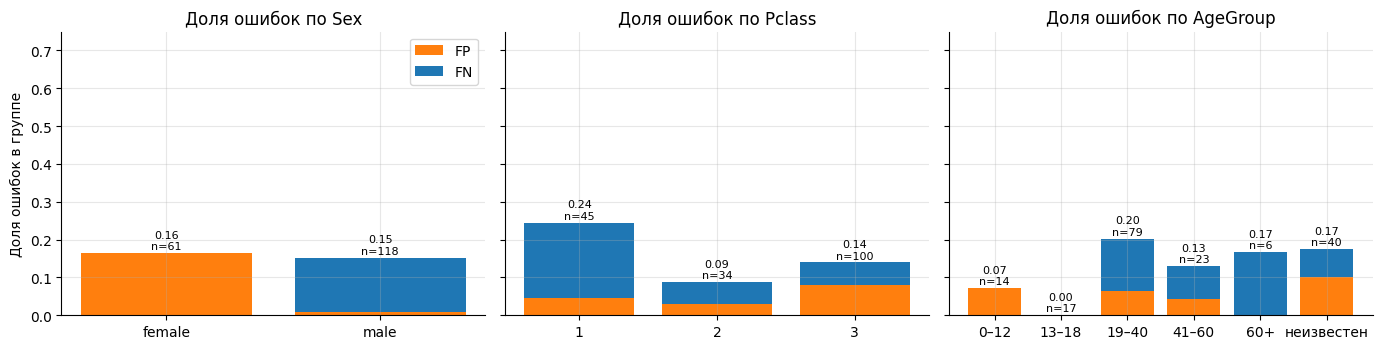

                n  FP  FN  доля_ошибок
Sex    Pclass                         
female 1       15   1   0         0.07
       2       18   1   0         0.06
       3       28   8   0         0.29
male   1       30   1   9         0.33
       2       16   0   2         0.12
       3       72   0   6         0.08

FN — выжили, но предсказан «погиб» (самые уверенные ошибки):


,Name,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived,Pred,score
271,"Tornquist, Mr. William Henry",3,male,25.0,0,0,0.00,S,1,0,-1.02
17,"Williams, Mr. Charles Eugene",2,male,NaN,0,0,13.00,S,1,0,-1.01
804,"Hedman, Mr. Oskar Arvid",3,male,27.0,0,0,6.98,S,1,0,-1.01


FP — погибли, но предсказан «выжил» (самые уверенные ошибки):


,Name,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived,Pred,score
297,"Allison, Miss. Helen Loraine",1,female,2.0,1,2,151.55,S,0,1,1.27
501,"Canavan, Miss. Mary",3,female,21.0,0,0,7.75,Q,0,1,1.07
199,"Yrois, Miss. Henriette (""Mrs Harbeck"")",2,female,24.0,0,0,13.00,S,0,1,1.03


In [9]:
best_name = leaderboard.drop(index="Dummy baseline")["F1"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Лучшая модель: {best_name}")
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"FPR (погибшие, названные выжившими) = {fp/(fp+tn):.3f};  FNR (пропущенные выжившие) = {fn/(fn+tp):.3f}")

test = df.loc[X_test.index, ["Name", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]].copy()
test["Pred"] = pred
test["FP"] = ((test.Pred == 1) & (test.Survived == 0)).astype(int)
test["FN"] = ((test.Pred == 0) & (test.Survived == 1)).astype(int)
test["Error"] = test.FP + test.FN
test["AgeGroup"] = pd.cut(test.Age, [0, 12, 18, 40, 60, 100], labels=["0–12", "13–18", "19–40", "41–60", "60+"]).astype(object).fillna("неизвестен")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, col in zip(axes, ["Sex", "Pclass", "AgeGroup"]):
    g = test.groupby(col).agg(n=("Error", "size"), FP=("FP", "sum"), FN=("FN", "sum"), Error=("Error", "sum"))
    ax.bar(g.index.astype(str), g.FP / g.n, color="tab:orange", label="FP")
    ax.bar(g.index.astype(str), g.FN / g.n, bottom=g.FP / g.n, color="tab:blue", label="FN")
    for i, (e, n) in enumerate(zip(g.Error / g.n, g.n)): ax.text(i, e + 0.01, f"{e:.2f}\nn={n}", ha="center", fontsize=8)
    ax.set_title(f"Доля ошибок по {col}"); ax.set_ylim(0, 0.75)
axes[0].legend(); axes[0].set_ylabel("Доля ошибок в группе")
plt.tight_layout(); plt.show()

print(test.groupby(["Sex", "Pclass"]).agg(n=("Error", "size"), FP=("FP", "sum"), FN=("FN", "sum"), доля_ошибок=("Error", "mean")).round(2).to_string())

sc = best.decision_function(X_test) if hasattr(best, "decision_function") and not hasattr(best, "predict_proba") else best.predict_proba(X_test)[:, 1]
test["score"] = sc
cols = ["Name", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived", "Pred", "score"]
print("\nFN — выжили, но предсказан «погиб» (самые уверенные ошибки):")
display(test[test.FN == 1].sort_values("score").head(3)[cols].round(2))
print("FP — погибли, но предсказан «выжил» (самые уверенные ошибки):")
display(test[test.FP == 1].sort_values("score", ascending=False).head(3)[cols].round(2))

**Типы и группы ошибок.** Модель (SVM) допускает 17 FN и 11 FP (FNR ≈ 0.25, FPR ≈ 0.10): выживших пропускает чаще, чем ошибочно «спасает» погибших. Ошибки структурированы по полу: **все 17 FN — мужчины, 10 из 11 FP — женщины**, то есть модель следует правилу «женщины выживают, мужчины погибают» и ошибается на исключениях. Сильнее всего ошибается на мужчинах 1-го класса (доля ошибок ≈ 0.33: многие выжили, а модель предсказывает гибель) и на женщинах 3-го класса (≈ 0.29: около половины погибли, а модель предсказывает спасение); в целом доля ошибок выше всего в 1-м классе (≈ 0.24) и у взрослых 19–40 лет (≈ 0.20). У детей и подростков ошибок почти нет — паттерн выражен ярко.

**Причины ошибок на примерах.**
- *FN* — одинокие мужчины 2–3-го класса с дешёвым билетом: профиль, при котором выживали лишь ≈ 12%; по признакам они неотличимы от погибших, исход определили ненаблюдаемые факторы (место на палубе, доступ к шлюпкам, случай). У `Tornquist` `Fare = 0` (аномалия или особая категория), у части пассажиров возраст неизвестен — исчезает один из сигналов.
- *FP* — женщины и девочка, чьи признаки (женщина/ребёнок, 1-й класс либо порт Queenstown) указывают на спасение, но которые погибли. `Allison, Miss. Helen Loraine` — двухлетняя девочка 1-го класса, «идеальный» профиль выжившего, однако в данных погибла она и мать, а брат выжил — исход определили обстоятельства, а не признаки. Женщины 3-го класса из Queenstown в данных выживали чаще (≈ 73% против ≈ 38% из Southampton), модель это усвоила, но часть таких пассажирок погибла.

Оставшиеся ошибки — в основном неустранимый шум: в данных нет факторов, реально определявших исход.

### Проверка на утечку и идентифицирующие признаки
Проверяем, не обеспечено ли качество признаками, идентифицирующими пассажира. Во-первых, `PassengerId`, `Name`, `Ticket`, `Cabin` в модель **не входят** (см. EDA). Во-вторых, переобучим лучшую модель с теми же гиперпараметрами без части признаков.

In [10]:
print("Уникальных значений у используемых признаков (из 891):", df[FEATURES].nunique().to_dict())

def run_variant(drop):
    num = [c for c in NUM_COLS if c not in drop]; cat = [c for c in CAT_COLS if c not in drop]
    pipe = Pipeline([("prep", make_preprocessor(best_name in ("SVM", "KNN"), num, cat)),
                     ("model", clone(best.named_steps["model"]))])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()
    return {"F1 CV (train)": cv_f1, "F1 test": f1_score(y_test, pipe.fit(X_train, y_train).predict(X_test))}

pd.DataFrame({"все 9 признаков": run_variant([]),
              "без Title и FamilySize": run_variant(["Title", "FamilySize"]),
              "без Fare": run_variant(["Fare"]),
              "без Sex и Title": run_variant(["Sex", "Title"])}).T.round(3)

Уникальных значений у используемых признаков (из 891): {'Pclass': 3, 'Sex': 2, 'Age': 88, 'SibSp': 7, 'Parch': 7, 'Fare': 248, 'Embarked': 3, 'Title': 5, 'FamilySize': 9}


,F1 CV (train),F1 test
все 9 признаков,0.768,0.788
без Title и FamilySize,0.757,0.750
без Fare,0.772,0.785
без Sex и Title,0.577,0.534


Используемые признаки не идентифицируют людей: у `Title` 5 значений, у `FamilySize` 9, у `Fare` 248 из 891 (числовая характеристика, одна цена соответствует многим пассажирам). Без `Fare` качество не меняется; без производных от `Name` и семьи (`Title`, `FamilySize`) падает умеренно; без `Sex` и `Title` — резко (≈ 0.53 на тесте), то есть результат обеспечивает легитимная информация о поле, классе и возрасте, доступная до события. **Высокое качество не связано с утечкой или запоминанием пассажиров.**

## 7. Итоговые выводы

1. Классы умеренно несбалансированы (38% выживших), поэтому оценка по F1 класса 1, стратифицированный split; пропуски в `Age`, `Cabin`, `Embarked`; признаки `PassengerId`, `Name`, `Ticket`, `Cabin` исключены как идентифицирующие или с косвенной утечкой.
2. Baseline (F1 = 0) побеждён всеми моделями; **порог F1 > 0.70 выполнен для всех пяти**: SVM 0.788, Decision Tree 0.776, Gradient Boosting 0.748, KNN 0.744, Random Forest 0.738. Лучшая — SVM, но различия между моделями лежат в пределах шума маленького теста.
3. Переобучены дерево без ограничений и Gradient Boosting; регуляризованное дерево, Random Forest, SVM и KNN — нет.
4. Главные признаки во всех деревьях: пол/обращение, класс, затем `Fare`, `Age`, `FamilySize` — согласуется с EDA; важность не означает причинность.
5. Ошибки лучшей модели — исключения из правила «женщины выживают, мужчины погибают»; утечки нет.

*Числа в тексте соответствуют запуску с `random_state=42`; на другой версии scikit-learn возможны небольшие отличия.*